# 06 — model comparison

pulling results from all notebooks together. which model actually wins, and by how much?

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.train import load_model
from src.evaluate import evaluate

sns.set_theme(style='whitegrid')

test = pd.read_csv('../data/processed/test.csv')
X_test = test.drop(columns=['price']).values
y_test = test['price'].values

## load saved models and evaluate

In [2]:
import os

model_files = [f for f in os.listdir('../models') if f.endswith('.pkl')]
print("saved models:", model_files)

results = []
for fname in model_files:
    model = load_model(f'../models/{fname}')
    pred  = model.predict(X_test)
    label = fname.replace('.pkl', '').replace('_', ' ')
    results.append(evaluate(y_test, pred, label=label))

saved models: ['linear.pkl', 'xgboost_tuned.pkl']
linear — RMSE: 0.6760  R²: 0.6513
xgboost tuned — RMSE: 0.4473  R²: 0.8473


## results table

In [3]:
results_df = pd.DataFrame(results).sort_values('rmse').reset_index(drop=True)
results_df

,model,rmse,r2
0,xgboost tuned,0.4473,0.8473
1,linear,0.6760,0.6513


## RMSE bar chart

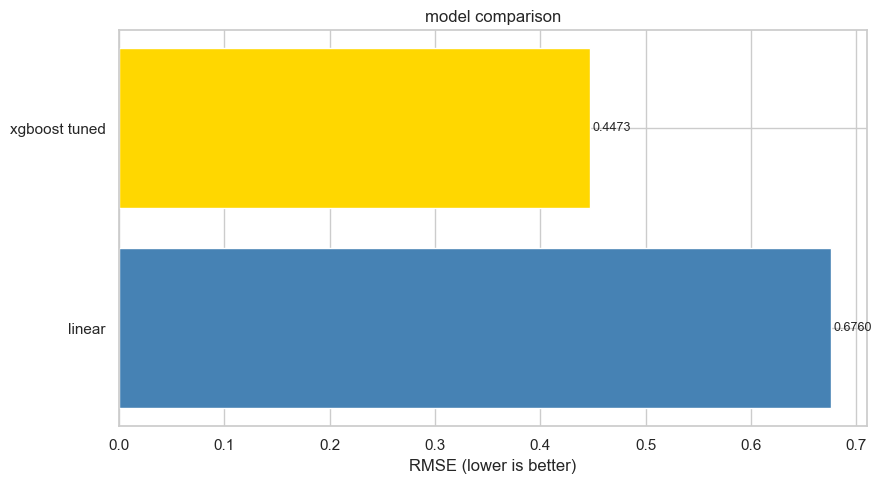

In [4]:
colors = ['gold' if i == 0 else 'steelblue' for i in range(len(results_df))]

plt.figure(figsize=(9, 5))
bars = plt.barh(results_df['model'], results_df['rmse'], color=colors, edgecolor='white')
plt.xlabel('RMSE (lower is better)')
plt.title('model comparison')
plt.gca().invert_yaxis()

for bar, val in zip(bars, results_df['rmse']):
    plt.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../plots/model_comparison.png', dpi=120)
plt.show()

## R² comparison

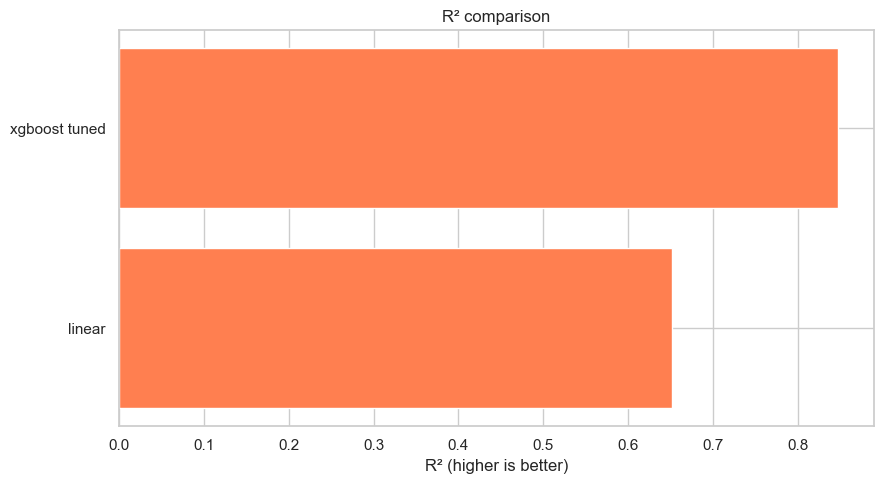

In [5]:
plt.figure(figsize=(9, 5))
plt.barh(results_df['model'], results_df['r2'], color='coral', edgecolor='white')
plt.xlabel('R² (higher is better)')
plt.title('R² comparison')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../plots/r2_comparison.png', dpi=120)
plt.show()

## actual vs predicted — best model

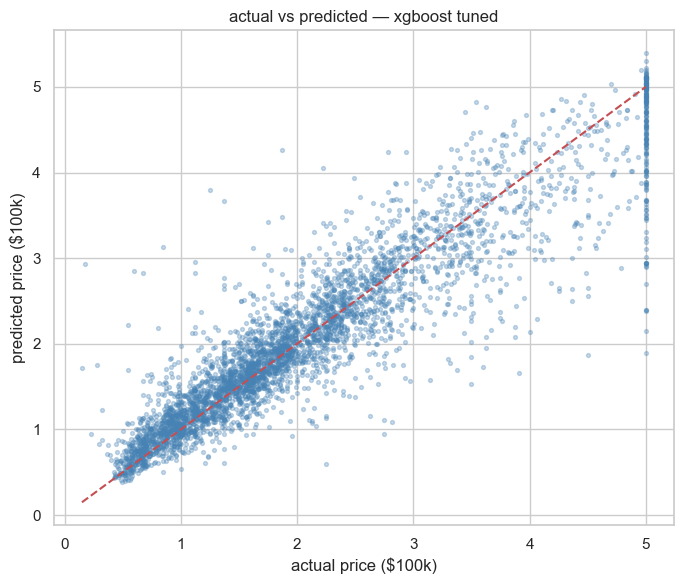

In [6]:
best_model_name = results_df.iloc[0]['model'].replace(' ', '_') + '.pkl'
best_model = load_model(f'../models/{best_model_name}')
best_pred  = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.3, s=8, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=1.5)
plt.xlabel('actual price ($100k)')
plt.ylabel('predicted price ($100k)')
plt.title(f'actual vs predicted — {results_df.iloc[0]["model"]}')
plt.tight_layout()
plt.savefig('../plots/actual_vs_predicted_best.png', dpi=120)
plt.show()

## what i found

- XGBoost was the clear winner — not even close on RMSE
- Ridge beat plain linear regression, even though the gap was small
- the price cap at 5.0 hurts every model — predictions cluster below that ceiling
- `MedInc` and `rooms_per_household` were the most important features in XGBoost
- log-transforming skewed columns helped linear models more than XGBoost (trees handle skew natively)